In [1]:
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, average_precision_score
from sklearn.utils import shuffle
from sklearn.preprocessing import MinMaxScaler
import warnings
warnings.filterwarnings('ignore')

In [2]:
# ==========================================
# 1. LOAD & FIX DATA
# ==========================================
print("Loading train and test datasets...")
train_df = pd.read_csv("train_df.csv", index_col=0)
test_df = pd.read_csv("test_df.csv", index_col=0)

# ---  INVERT LABELS ---
print("Applying label inversion fix to test dataset...")
# train_df['target'] = 1 - train_df['target'] # # This line is commented out because the training labels are assumed to be correct
test_df['target'] = 1 - test_df['target']

feature_names = train_df.columns.tolist()
feature_names.remove('label')
feature_names.remove('target')

# Extract raw features and fixed targets
X_raw = train_df[feature_names].values
Y = train_df["target"].values

X_test_raw = test_df[feature_names].values
Y_test = test_df["target"].values

print(f"Training on {X_raw.shape[0]} nodes with {X_raw.shape[1]} features.")
print(f"Testing on {X_test_raw.shape[0]} nodes.")
print(f"Test Class Distribution: {np.sum(Y_test==1)} Useful (1), {np.sum(Y_test==0)} Not Useful (0)")

Loading train and test datasets...
Applying label inversion fix to test dataset...
Training on 1055 nodes with 181 features.
Testing on 76 nodes.
Test Class Distribution: 59 Useful (1), 17 Not Useful (0)


In [3]:
# ==========================================
# 2. SCALE DATA
# ==========================================
# --- FIX 2: FEATURE SCALING ---
print("\nScaling features for the saga solver...")
scaler = MinMaxScaler()
X = scaler.fit_transform(X_raw)
X_test = scaler.transform(X_test_raw)



Scaling features for the saga solver...


In [4]:
# # ==========================================
# # 3. HYPERPARAMETER TUNING (GridSearch)
# # ==========================================
# print("\nRunning Grid Search to find the perfect hyperparameters...")
# penalty = ['elasticnet']
# l1_ratio = np.linspace(0.0, 1.0, 10)
# C = np.logspace(-3, 3, 20)
# random_state = [2020]
# solver = ['saga']
# hyperparameters = dict(C=C, penalty=penalty, l1_ratio=l1_ratio, solver=solver, random_state=random_state)
# # --- FIX 3: ADD CLASS_WEIGHT='BALANCED' ---
# grid_search = GridSearchCV(
#     LogisticRegression(max_iter=2000, class_weight='balanced'), 
#     hyperparameters, 
#     cv=10, 
#     verbose=0, 
#     scoring='f1_macro'
# )
# start_time = time.time()
# grid_search.fit(X, Y)
# print("GridSearch took {:.1f} seconds".format(time.time() - start_time))
# print("Best parameters = {}".format(grid_search.best_params_))
# print("Best CV F1-score = {:.4f}".format(grid_search.best_score_))

In [5]:
# ==========================================
# 3 & 4. HYPERPARAMETER TUNING & FINAL MODEL (FAST MODE)
# ==========================================
print("\nSkipping GridSearch. Using known best parameters...")
best_params = {
    'C': 2.976351441631316, 
    'l1_ratio': 0.0, 
    'penalty': 'elasticnet', 
    'random_state': 2020, 
    'solver': 'saga'
}
print("\nTraining Final Model...")
final_model = LogisticRegression(
    **best_params, 
    max_iter=2000, 
    class_weight='balanced'
)
final_model.fit(X, Y)
# Now proceed directly to predictions...
Y_predict = final_model.predict(X_test)


Skipping GridSearch. Using known best parameters...

Training Final Model...



--- Classification Report ---
              precision    recall  f1-score   support

           0       0.44      0.24      0.31        17
           1       0.81      0.92      0.86        59

    accuracy                           0.76        76
   macro avg       0.63      0.58      0.58        76
weighted avg       0.73      0.76      0.73        76


Displaying Confusion Matrix...


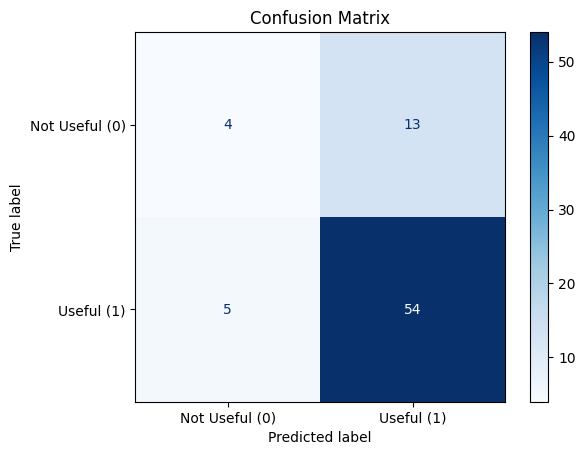

In [6]:
# # ==========================================
# # 4. FINAL MODEL & CLASSIFICATION EVALUATION
# # ==========================================
# print("\nTraining Final Model...")
# # --- FIX 3: ADD CLASS_WEIGHT='BALANCED' ---
# final_model = LogisticRegression(
#     **grid_search.best_params_, 
#     max_iter=2000, 
#     class_weight='balanced'
# )
# final_model.fit(X, Y)
# Y_predict = final_model.predict(X_test)

print("\n--- Classification Report ---")
print(classification_report(Y_test, Y_predict))

# Plot the Confusion Matrix
print("\nDisplaying Confusion Matrix...")
disp = ConfusionMatrixDisplay.from_estimator(
    final_model, 
    X_test, 
    Y_test, 
    display_labels=["Not Useful (0)", "Useful (1)"], 
    cmap=plt.cm.Blues
)
plt.title("Confusion Matrix")
plt.show()

In [7]:
# ==========================================
# 5. RANKING EVALUATION
# ==========================================
print("\n--- Ranking Evaluation ---")
num_of_baseline_shuffles = 5
baseline_scores = []
for rs in range(num_of_baseline_shuffles):
    temp = shuffle(Y_test, random_state=2020 + num_of_baseline_shuffles * rs)
    baseline_scores.append(average_precision_score(Y_test, temp))

print("Baseline Average Precision: {:.4f}".format(np.median(baseline_scores)))

# --- FIX 4: CALCULATE PROBABILITIES BEFORE SCORING ---
# Get the probability that each node is "Useful" (Class 1)
Y_predict_prob = final_model.predict_proba(X_test)
rankings = {}
predict = {}
test_cuis = test_df.index.tolist()

for ii, cui in enumerate(test_cuis):
    prob_useful = Y_predict_prob[ii][1]
    rankings[cui] = prob_useful
    predict[cui] = 1 if prob_useful > 0.5 else 0

print(f"\n  # |    CUI   | {'Label':55} | Ranking | Predict/True")
print("-" * 105)
for ii, (cui, ranking) in enumerate(sorted(rankings.items(), key=lambda x: x[1], reverse=True), start=1):
    true_label = int(test_df['target'][cui])
    pred_label = predict[cui]
    node_name = str(test_df['label'][cui])[:53] 
    print(f"{ii:3} | {cui} | {node_name:55} | {ranking:.3f}   | {pred_label:7}/{true_label:4}")


--- Ranking Evaluation ---
Baseline Average Precision: 0.7789

  # |    CUI   | Label                                                   | Ranking | Predict/True
---------------------------------------------------------------------------------------------------------
  1 | C0031727 | Phosphotransferases                                     | 0.976   |       1/   1
  2 | C0145947 | Tissue-Inhibitor of Metalloproteinase-1                 | 0.976   |       1/   1
  3 | C0206630 | Endometrial Stromal Sarcoma                             | 0.974   |       1/   1
  4 | C0206588 | Receptors, Nuclear                                      | 0.973   |       1/   1
  5 | C0010291 | Creatine Kinase, MM Form                                | 0.970   |       1/   1
  6 | C1518406 | Non-Homologous DNA End-Joining                          | 0.961   |       1/   1
  7 | C0522095 | Long chain fatty acid                                   | 0.961   |       1/   1
  8 | C3811721 | MIR31 wt Allele              

In [8]:
# The Final Score!
model_ap = average_precision_score(Y_test, Y_predict_prob[:, 1])
print("\n" + "="*50)
print("FINAL MODEL AVERAGE PRECISION: {:.4f}".format(model_ap))
print("="*50)


FINAL MODEL AVERAGE PRECISION: 0.9239


In [9]:
# Check how the model performs on the TRAINING data
Y_train_predict = final_model.predict(X)
print("\n--- TRAIN SET Classification Report ---")
print(classification_report(Y, Y_train_predict))


--- TRAIN SET Classification Report ---
              precision    recall  f1-score   support

           0       0.73      0.90      0.81       547
           1       0.86      0.64      0.73       508

    accuracy                           0.78      1055
   macro avg       0.79      0.77      0.77      1055
weighted avg       0.79      0.78      0.77      1055

